# Audit landmark và AU sau STR

Đọc trực tiếp STR manifest và LibreFace AU cache của run E3. Notebook so sánh landmark kế thừa từ donor với landmark MTCNN detect lại, hiển thị spatial mask 7×7 thực tế của pipeline và xuất review queue.

In [ ]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from facenet_pytorch import MTCNN
import torch

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from cs_aualign_vit.data.au_guidance import AU_COLUMNS, AU_IDS, build_au_mask
from cs_aualign_vit.data.str_patches import compute_rois

RUN_DIR = ROOT / 'runs/adaptation/e3-both-100epochs-seed42'
STR_MANIFEST = RUN_DIR / 'str/manifest.jsonl'
AU_CACHE = RUN_DIR / 'source_au_cache.csv'
OUTPUT_DIR = RUN_DIR / 'str/audit'
SAMPLE_SIZE = 150
SEED = 42
SHOW_FIRST = 24

assert STR_MANIFEST.exists(), f'Không tìm thấy STR manifest: {STR_MANIFEST}'
assert AU_CACHE.exists(), f'Không tìm thấy AU cache: {AU_CACHE}'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

/home/dangnha/cd-fer/CS-AUAlign-ViT/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Đọc dữ liệu và lấy mẫu

Manifest STR đã chứa đường dẫn ảnh, landmark kế thừa, donor/target provenance, class và round. Không cần tạo manifest audit riêng hoặc đọc ExpW evaluation manifest.

In [ ]:
with STR_MANIFEST.open(encoding='utf-8') as stream:
    manifest = pd.DataFrame(json.loads(line) for line in stream if line.strip())

required = {'sample_id', 'processed_path', 'landmarks_crop', 'round_id', 'class_name', 'donor_id', 'target_id'}
assert required <= set(manifest), f'STR manifest thiếu cột: {sorted(required - set(manifest))}'
manifest['str_path'] = manifest.processed_path.map(lambda value: (STR_MANIFEST.parent / value).resolve())
missing = manifest[~manifest.str_path.map(Path.exists)]
assert missing.empty, f'{len(missing)} ảnh STR không tồn tại; ví dụ: {missing.str_path.iloc[0]}'

n = min(SAMPLE_SIZE, len(manifest))
round_count = manifest.round_id.nunique()
per_round = int(np.ceil(n / round_count))
parts = [group.sample(n=min(per_round, len(group)), random_state=SEED)
         for _, group in manifest.groupby('round_id')]
sampled = pd.concat(parts, ignore_index=True)
if len(sampled) < n:
    remaining = manifest[~manifest.sample_id.isin(sampled.sample_id)]
    sampled = pd.concat([sampled, remaining.sample(n=n - len(sampled), random_state=SEED)], ignore_index=True)
sampled = sampled.sample(n=n, random_state=SEED).reset_index(drop=True)
print(f'Audit {len(sampled)}/{len(manifest)} ảnh STR')
sampled.groupby(['round_id', 'class_name']).size().rename('count').to_frame()

Audit 89/89 ảnh STR


,,count
round_id,class_name,
1,fear,44
2,fear,30
3,fear,15


In [ ]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
mtcnn = MTCNN(keep_all=False, device=device)
au_table = pd.read_csv(AU_CACHE).set_index('sample_id', drop=False)
assert set(AU_COLUMNS) <= set(au_table), 'AU cache không đúng schema của pipeline'

def detect_landmarks(path):
    image = Image.open(path).convert('RGB')
    _, _, points = mtcnn.detect(image, landmarks=True)
    return image, None if points is None else np.asarray(points[0], dtype=float)

def normalized_landmark_error(reference, detected):
    if detected is None:
        return np.nan
    eye_distance = np.linalg.norm(reference[0] - reference[1])
    return np.nan if eye_distance == 0 else np.linalg.norm(reference - detected, axis=1).mean() / eye_distance

def get_au(sample_id):
    if sample_id not in au_table.index:
        return np.zeros(len(AU_IDS)), False, 'missing'
    row = au_table.loc[sample_id]
    if row.status != 'success':
        return np.zeros(len(AU_IDS)), False, str(row.get('reason', 'failed'))
    return row[list(AU_COLUMNS)].to_numpy(dtype=float), True, ''

def raw_mask(landmarks, image_size):
    if landmarks is None:
        return np.zeros((49, len(AU_IDS))), False
    mask, valid = build_au_mask(landmarks, image_size)
    if not valid:
        return np.zeros((49, len(AU_IDS))), False
    return mask.numpy(), True

def weighted_mask(mask, au_values):
    weights = np.asarray(au_values, dtype=float) / 5.0
    return (mask * weights).sum(axis=1).reshape(7, 7)

def mask_similarity(reference, detected, valid):
    if not valid:
        return np.nan, np.nan
    a, b = reference.ravel(), detected.ravel()
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    cosine = np.dot(a, b) / denominator if denominator else np.nan
    return cosine, np.abs(a - b).mean()

def landmark_to_patch_distance(inherited, detected, image_size):
    if detected is None:
        return [np.nan] * 4
    rois = np.asarray(compute_rois(inherited, image_size), dtype=float)
    if rois.shape != (4, 4):
        return [np.nan] * 4
    anchors = np.vstack([detected[0], detected[1], detected[2], detected[3:5].mean(axis=0)])
    centers = np.column_stack(((rois[:, 0] + rois[:, 2]) / 2, (rois[:, 1] + rois[:, 3]) / 2))
    diagonals = np.linalg.norm(rois[:, 2:4] - rois[:, 0:2], axis=1)
    return np.divide(np.linalg.norm(anchors - centers, axis=1), diagonals,
                     out=np.full(4, np.nan), where=diagonals > 0).tolist()

## Detect lại landmark và tính NME

NME là khoảng cách trung bình giữa hai bộ 5 điểm, chuẩn hóa bằng khoảng cách hai mắt của landmark kế thừa. AU intensity giữ nguyên thang LibreFace 0–5.

In [ ]:
records = []
for row in sampled.itertuples(index=False):
    image, redetected = detect_landmarks(row.str_path)
    inherited = np.asarray(row.landmarks_crop, dtype=float)
    au_values, au_valid, au_reason = get_au(row.sample_id)
    inherited_mask, inherited_mask_valid = raw_mask(inherited, image.size)
    detected_mask, detected_mask_valid = raw_mask(redetected, image.size)
    mask_cosine, mask_mae = mask_similarity(
        inherited_mask, detected_mask, inherited_mask_valid and detected_mask_valid)
    patch_distances = landmark_to_patch_distance(inherited, redetected, image.size)
    records.append({
        **row._asdict(),
        'image': image,
        'inherited_landmarks': inherited,
        'redetected_landmarks': redetected,
        'nme': normalized_landmark_error(inherited, redetected),
        'mtcnn_failed': redetected is None,
        'au_values': au_values,
        'au_valid': au_valid,
        'au_reason': au_reason,
        'au_max': au_values.max() if au_valid else np.nan,
        'au_mean': au_values.mean() if au_valid else np.nan,
        'inherited_mask': inherited_mask,
        'detected_mask': detected_mask,
        'mask_cosine': mask_cosine,
        'mask_mae': mask_mae,
        'patch_distance_eye_left': patch_distances[0],
        'patch_distance_eye_right': patch_distances[1],
        'patch_distance_nose': patch_distances[2],
        'patch_distance_mouth': patch_distances[3],
        'patch_distance_mean': np.nanmean(patch_distances) if np.isfinite(patch_distances).any() else np.nan,
    })
results = pd.DataFrame(records)
results[['sample_id', 'round_id', 'class_name', 'nme', 'patch_distance_mean',
         'mask_cosine', 'mask_mae', 'mtcnn_failed', 'au_valid']].head()

,sample_id,round_id,class_name,nme,patch_distance_mean,mask_cosine,mask_mae,mtcnn_failed,au_valid
0,ee448c9c9a8b4b71299b52326745564b48a53d24f89c11...,2,fear,0.196587,0.737710,0.962640,0.047076,False,True
1,779180975d4d40e0bc231fbd729254ed4c1a04e09bcbd9...,2,fear,0.121358,0.600967,0.979579,0.031585,False,True
2,de1eebfbfc30ed868536041d2814790315945bf35184b5...,2,fear,0.419431,1.051139,0.864408,0.084434,False,True
3,9a5abb3dfcac54c76f3dd87300e466828eafc1668c8b97...,1,fear,0.186559,0.848192,0.934458,0.075014,False,True
4,d94104dab1900b4d63ef0f8cea8e879a01e3dac6eb591a...,2,fear,0.396763,1.014038,0.888703,0.066786,False,True


## Tổng hợp theo STR round

Báo cáo median và p90 vì các chỉ số sai khác dễ bị chi phối bởi một số ít ca cực đoan. Khoảng cách tới ROI được chuẩn hóa theo đường chéo ROI và chỉ dùng để sàng lọc hình học; nó không phải ground truth về landmark.

In [ ]:
round_summary = (results.groupby('round_id')
    .agg(sample_size=('sample_id', 'size'),
         nme_median=('nme', 'median'),
         nme_p90=('nme', lambda values: values.quantile(0.90)),
         patch_distance_median=('patch_distance_mean', 'median'),
         patch_distance_p90=('patch_distance_mean', lambda values: values.quantile(0.90)),
         mask_cosine_median=('mask_cosine', 'median'),
         mask_cosine_p10=('mask_cosine', lambda values: values.quantile(0.10)),
         mask_mae_median=('mask_mae', 'median'),
         mask_mae_p90=('mask_mae', lambda values: values.quantile(0.90)),
         mtcnn_failure_rate=('mtcnn_failed', 'mean'))
    .reset_index())
round_summary

,round_id,sample_size,nme_median,nme_p90,patch_distance_median,patch_distance_p90,mask_cosine_median,mask_cosine_p10,mask_mae_median,mask_mae_p90,mtcnn_failure_rate
0,1,44,0.189097,0.310130,0.687426,0.884592,0.960486,0.891855,0.049729,0.094971,0.159091
1,2,30,0.210010,0.396763,0.727466,1.014038,0.946698,0.880189,0.054829,0.079563,0.300000
2,3,15,0.160090,0.272953,0.790061,0.831388,0.953465,0.905259,0.051032,0.070010,0.266667


## AU validity trên toàn bộ STR manifest

`guidance_valid` yêu cầu LibreFace thành công và spatial mask từ landmark kế thừa hợp lệ. Thống kê này dùng toàn bộ STR records, không chỉ mẫu MTCNN audit.

In [ ]:
def au_status(sample_id):
    if sample_id not in au_table.index:
        return 'missing'
    return str(au_table.loc[sample_id].status)

def inherited_mask_valid(row):
    with Image.open(row.str_path) as image:
        _, valid = build_au_mask(row.landmarks_crop, image.size)
    return valid

validity = manifest[['sample_id', 'round_id', 'str_path', 'landmarks_crop']].copy()
validity['au_status'] = validity.sample_id.map(au_status)
validity['mask_valid'] = [inherited_mask_valid(row) for row in validity.itertuples(index=False)]
validity['guidance_valid'] = validity.au_status.eq('success') & validity.mask_valid
au_validity_by_round = (validity.groupby('round_id')
    .agg(total=('sample_id', 'size'),
         libreface_success=('au_status', lambda values: values.eq('success').sum()),
         libreface_failed=('au_status', lambda values: values.eq('failed').sum()),
         libreface_missing=('au_status', lambda values: values.eq('missing').sum()),
         guidance_valid=('guidance_valid', 'sum'),
         guidance_valid_rate=('guidance_valid', 'mean'))
    .reset_index())
au_validity_by_round

,round_id,total,libreface_success,libreface_failed,libreface_missing,guidance_valid,guidance_valid_rate
0,1,44,43,1,0,43,0.977273
1,2,30,29,1,0,29,0.966667
2,3,15,10,5,0,10,0.666667


/tmp/ipykernel_794049/2809966467.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, 3, figsize=(15, 5))


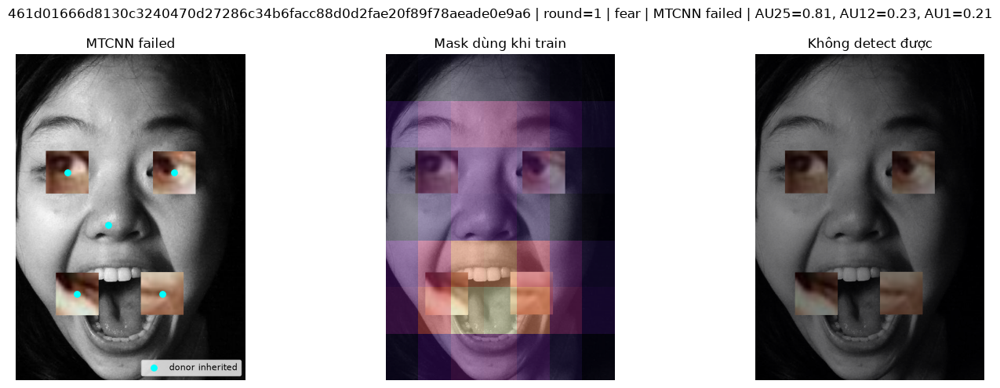

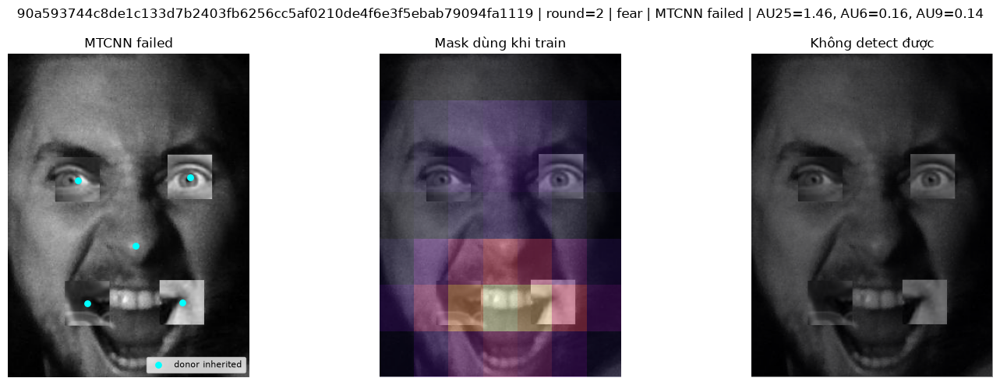

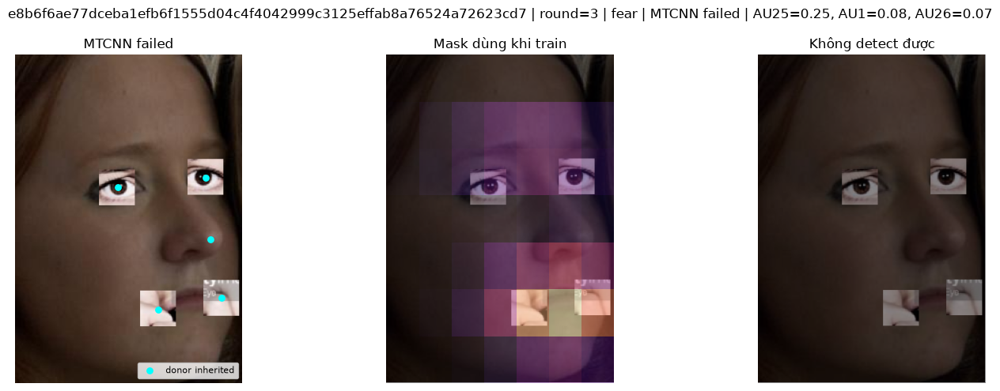

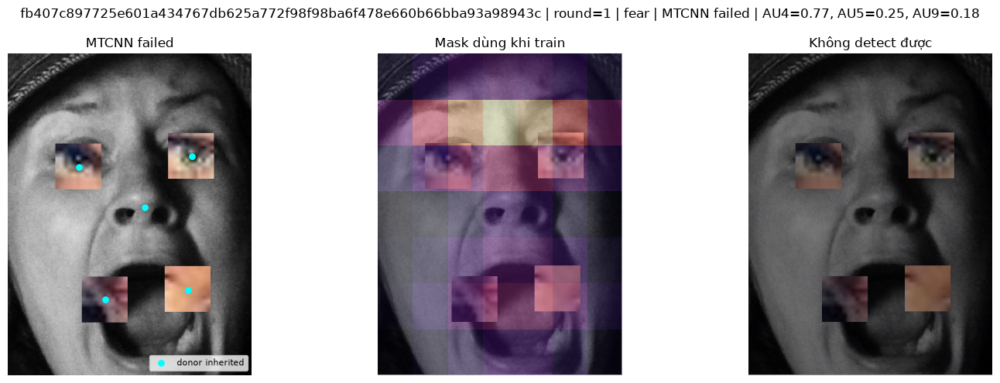

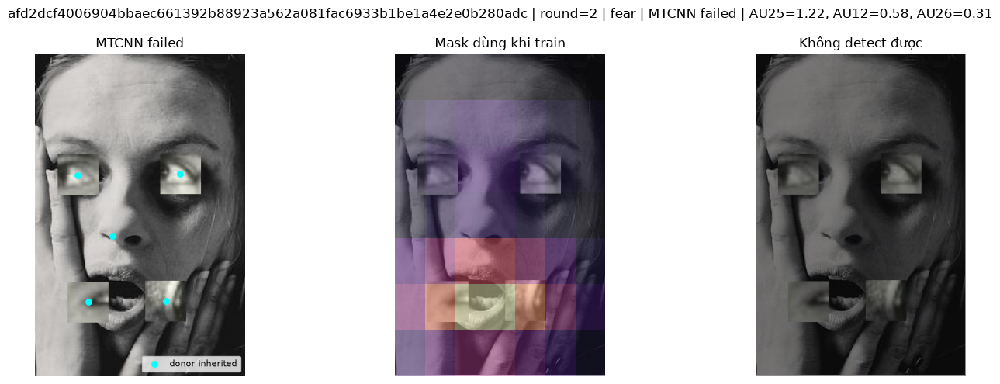

...

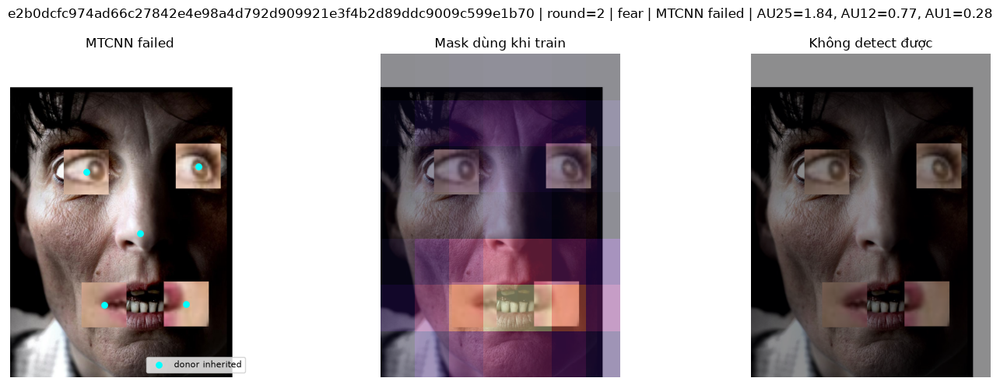

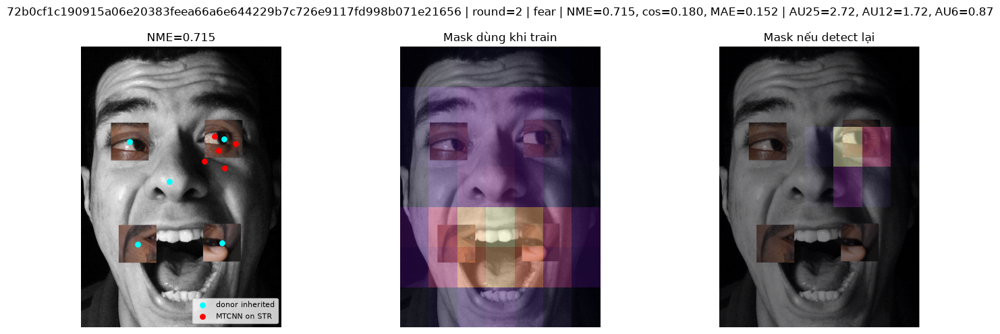

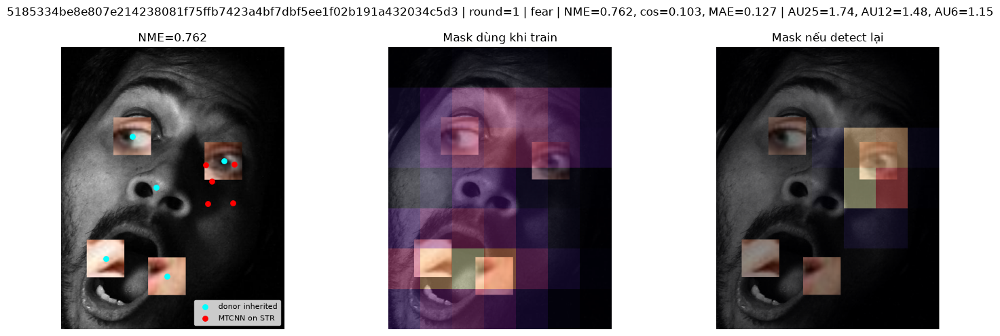

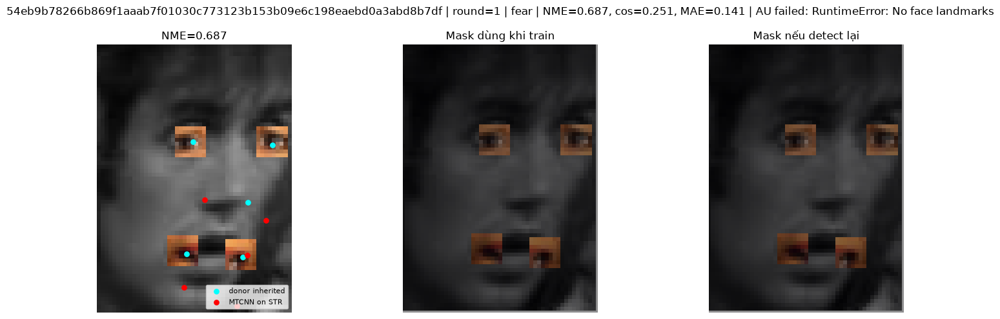

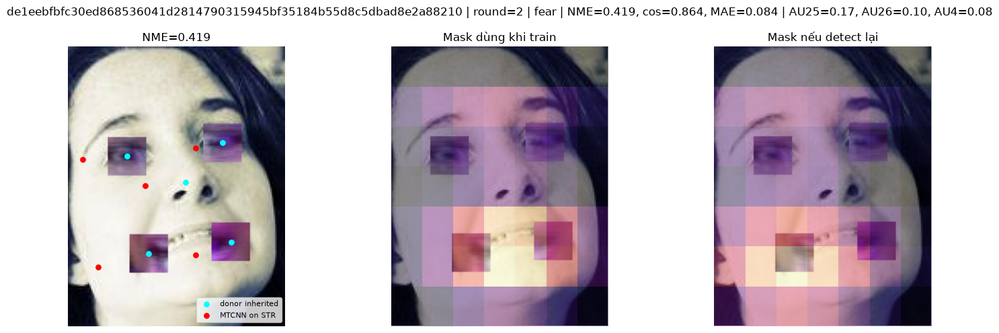

In [ ]:
def show_record(record):
    inherited_mask = weighted_mask(record.inherited_mask, record.au_values)
    detected_mask = weighted_mask(record.detected_mask, record.au_values)
    detected_valid = np.isfinite(record.mask_cosine)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(record.image)
    axes[0].scatter(record.inherited_landmarks[:, 0], record.inherited_landmarks[:, 1], c='cyan', s=28, label='donor inherited')
    if record.redetected_landmarks is not None:
        axes[0].scatter(record.redetected_landmarks[:, 0], record.redetected_landmarks[:, 1], c='red', s=28, label='MTCNN on STR')
    axes[0].set_title(f'NME={record.nme:.3f}' if pd.notna(record.nme) else 'MTCNN failed')
    axes[0].legend(loc='lower right', fontsize=8)
    for axis, mask, title in [
        (axes[1], inherited_mask, 'Mask dùng khi train'),
        (axes[2], detected_mask, 'Mask nếu detect lại' if detected_valid else 'Không detect được'),
    ]:
        axis.imshow(record.image)
        axis.imshow(mask, cmap='magma', alpha=0.45, extent=(0, record.image.width, record.image.height, 0), vmin=0)
        axis.set_title(title)
    for axis in axes:
        axis.axis('off')
    strongest = np.argsort(record.au_values)[::-1][:3]
    au_text = ', '.join(f'AU{AU_IDS[i]}={record.au_values[i]:.2f}' for i in strongest) if record.au_valid else f'AU failed: {record.au_reason}'
    metrics = f'NME={record.nme:.3f}, cos={record.mask_cosine:.3f}, MAE={record.mask_mae:.3f}' if pd.notna(record.nme) else 'MTCNN failed'
    fig.suptitle(f'{record.sample_id} | round={record.round_id} | {record.class_name} | {metrics} | {au_text}')
    plt.tight_layout()

ranked = results.copy()
ranked['anomaly_score'] = (ranked.nme.rank(pct=True)
                           + ranked.mask_mae.rank(pct=True)
                           + (1 - ranked.mask_cosine.rank(pct=True)))
ranked = ranked.sort_values(['mtcnn_failed', 'anomaly_score'], ascending=[False, False])
for record in ranked.head(SHOW_FIRST).itertuples():
    show_record(record)

## Xuất kết quả

Review queue gồm MTCNN failure, LibreFace failure và 10% ảnh có NME cao nhất trong mẫu. P90 chỉ là ngưỡng sàng lọc của mẫu audit.

In [ ]:
valid_nme = results.nme.dropna()
nme_cutoff = valid_nme.quantile(0.90) if len(valid_nme) else np.nan
cosine_cutoff = results.mask_cosine.quantile(0.10)
mae_cutoff = results.mask_mae.quantile(0.90)
results['needs_review'] = (results.mtcnn_failed | ~results.au_valid
                           | (results.nme >= nme_cutoff)
                           | (results.mask_cosine <= cosine_cutoff)
                           | (results.mask_mae >= mae_cutoff))
columns = ['sample_id', 'str_path', 'round_id', 'class_name', 'donor_id', 'target_id',
           'nme', 'patch_distance_eye_left', 'patch_distance_eye_right',
           'patch_distance_nose', 'patch_distance_mouth', 'patch_distance_mean',
           'mask_cosine', 'mask_mae', 'mtcnn_failed', 'au_valid', 'au_reason',
           'au_max', 'au_mean', 'needs_review']
results[columns].to_csv(OUTPUT_DIR / 'audit_results.csv', index=False)
review_queue = results.loc[results.needs_review, columns].sort_values(
    ['mtcnn_failed', 'au_valid', 'nme', 'mask_mae'], ascending=[False, True, False, False])
review_queue.to_csv(OUTPUT_DIR / 'review_queue.csv', index=False)
round_summary.to_csv(OUTPUT_DIR / 'round_summary.csv', index=False)
au_validity_by_round.to_csv(OUTPUT_DIR / 'au_validity_by_round.csv', index=False)
pd.Series({
    'sample_size': len(results),
    'mtcnn_failures': int(results.mtcnn_failed.sum()),
    'libreface_failures': int((~results.au_valid).sum()),
    'median_nme': valid_nme.median() if len(valid_nme) else np.nan,
    'p90_nme': nme_cutoff,
    'median_mask_cosine': results.mask_cosine.median(),
    'median_mask_mae': results.mask_mae.median(),
    'review_queue_size': len(review_queue),
}).to_frame('value')

,value
sample_size,89.000000
mtcnn_failures,20.000000
libreface_failures,7.000000
median_nme,0.190829
p90_nme,0.326188
median_mask_cosine,0.950523
median_mask_mae,0.051032
review_queue_size,38.000000


## Review bằng mắt: donor | target | STR

Mỗi hàng đặt crop donor RAF-DB, crop target ExpW và ảnh STR cạnh nhau. Khung màu lần lượt là ROI mắt trái, mắt phải, mũi và miệng. Chấm cyan là landmark được lưu trong manifest; chấm đỏ trên STR là MTCNN detect lại. Dữ liệu gốc được đọc từ data host `/home/hung/FER-DomainAdaptation/CS-AUAlign-ViT`.

In [ ]:
SOURCE_MANIFEST = ROOT / 'data/processed/raf-v5-deduplicated/processed.jsonl'
TARGET_MANIFEST = ROOT / 'data/processed/expw-v1/processed.jsonl'
if not TARGET_MANIFEST.exists():
    TARGET_MANIFEST = (ROOT.parents[1] / 'FER-DomainAdaptation/CS-AUAlign-ViT/data/processed/expw-v1/processed.jsonl').resolve()
REVIEW_PAGE = 0
REVIEW_PAGE_SIZE = 4

assert SOURCE_MANIFEST.exists(), f'Không tìm thấy source manifest: {SOURCE_MANIFEST}'

def load_index(path):
    with path.open(encoding='utf-8') as stream:
        rows = [json.loads(line) for line in stream if line.strip()]
    return {row['sample_id']: {**row, '_path': (path.parent / row['processed_path']).resolve()}
            for row in rows if row.get('usable') and row.get('processed_path')}

source_index = load_index(SOURCE_MANIFEST)
target_index = load_index(TARGET_MANIFEST) if TARGET_MANIFEST.exists() else {}
missing_donors = sorted(set(review_queue.donor_id) - set(source_index))
missing_targets = sorted(set(review_queue.target_id) - set(target_index))
assert not missing_donors, f'Donor không có trong source manifest: {missing_donors[:3]}'
if missing_targets:
    print(f'Không có crop ExpW cho {len(missing_targets)} review records; '
          f'cần mount data host tại {TARGET_MANIFEST.parent}')

Không có crop ExpW cho 38 review records; cần mount data host tại /home/dangnha/cd-fer/CS-AUAlign-ViT/data/processed/expw-v1


Page 1/10: rows 1–4/38


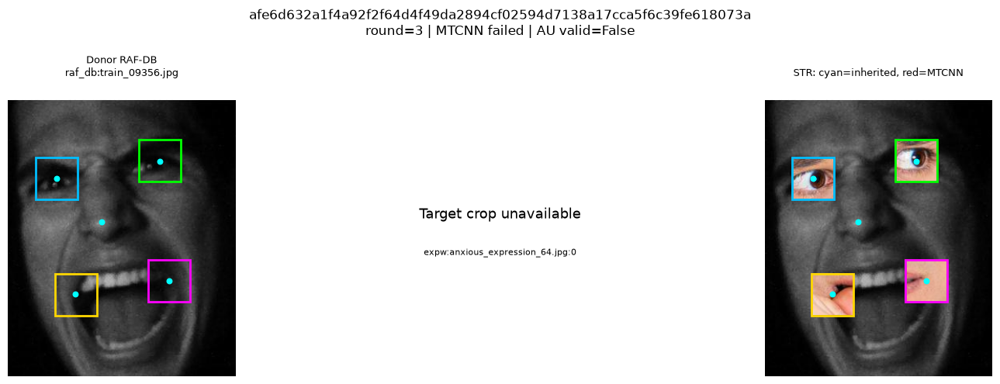

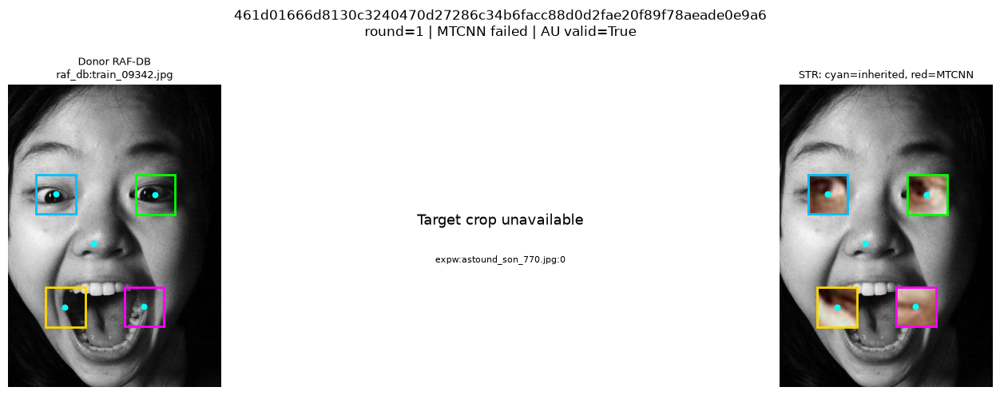

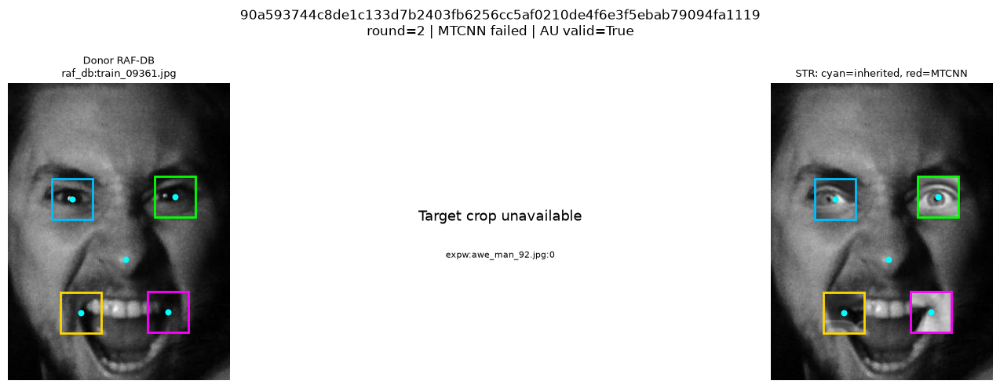

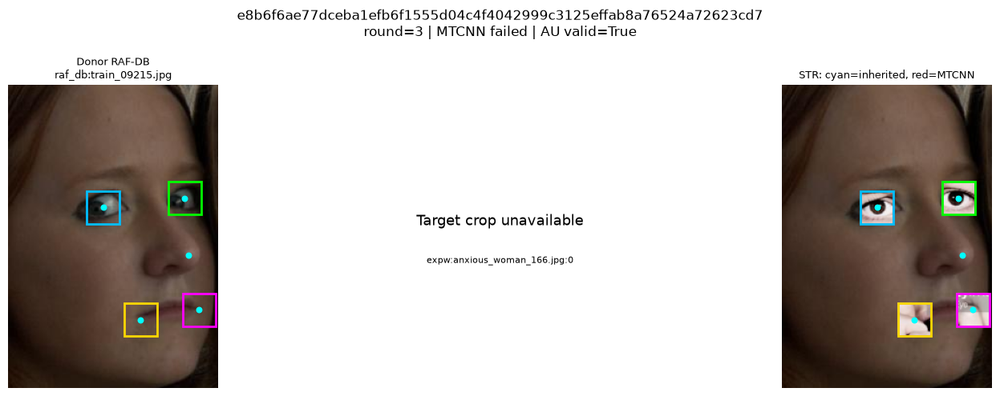

In [ ]:
from matplotlib.patches import Rectangle

ROI_NAMES = ('left eye', 'right eye', 'nose', 'mouth')
ROI_COLORS = ('deepskyblue', 'lime', 'gold', 'magenta')

def draw_face(axis, image, landmarks, *, redetected=None, title=''):
    axis.imshow(image)
    rois = compute_rois(landmarks, image.size)
    for name, color, (left, top, right, bottom) in zip(ROI_NAMES, ROI_COLORS, rois):
        axis.add_patch(Rectangle((left, top), right - left, bottom - top,
                                 fill=False, edgecolor=color, linewidth=2, label=name))
    points = np.asarray(landmarks, dtype=float)
    axis.scatter(points[:, 0], points[:, 1], c='cyan', s=22)
    if redetected is not None:
        axis.scatter(redetected[:, 0], redetected[:, 1], c='red', marker='x', s=35)
    axis.set_title(title, fontsize=9)
    axis.axis('off')

def show_triplet(record):
    donor = source_index[record.donor_id]
    target = target_index.get(record.target_id)
    donor_image = Image.open(donor['_path']).convert('RGB')
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    draw_face(axes[0], donor_image, donor['landmarks_crop'], title=f'Donor RAF-DB\n{record.donor_id}')
    if target is not None:
        target_image = Image.open(target['_path']).convert('RGB')
        draw_face(axes[1], target_image, target['landmarks_crop'], title=f'Target ExpW\n{record.target_id}')
    else:
        axes[1].text(0.5, 0.55, 'Target crop unavailable', ha='center', va='center', fontsize=13)
        axes[1].text(0.5, 0.42, record.target_id, ha='center', va='center', fontsize=8, wrap=True)
        axes[1].axis('off')
    draw_face(axes[2], record.image, record.inherited_landmarks,
              redetected=record.redetected_landmarks, title='STR: cyan=inherited, red=MTCNN')
    metrics = (f'round={record.round_id} | NME={record.nme:.3f} | '
               f'mask cosine={record.mask_cosine:.3f} | MAE={record.mask_mae:.3f}')
    if record.mtcnn_failed:
        metrics = f'round={record.round_id} | MTCNN failed | AU valid={record.au_valid}'
    fig.suptitle(f'{record.sample_id}\n{metrics}')
    plt.tight_layout()
    plt.show()

start = REVIEW_PAGE * REVIEW_PAGE_SIZE
page_ids = review_queue.sample_id.iloc[start:start + REVIEW_PAGE_SIZE]
print(f'Page {REVIEW_PAGE + 1}/{int(np.ceil(len(review_queue) / REVIEW_PAGE_SIZE))}: '
      f'rows {start + 1}–{min(start + REVIEW_PAGE_SIZE, len(review_queue))}/{len(review_queue)}')
page = results.set_index('sample_id').loc[page_ids].reset_index()
for record in page.itertuples(index=False):
    show_triplet(record)

## Ghi kết quả review

Điền `REVIEW_DECISIONS` theo `sample_id`, rồi chạy cell để tạo `manual_review.csv`. Nhãn gợi ý: `str_composite_error`, `mtcnn_redetect_error`, `libreface_error`, `looks_consistent`, `unclear`. Một ảnh có thể dùng nhiều nhãn, phân cách bằng dấu `;`.

In [ ]:
REVIEW_DECISIONS = {
    # 'sample_id': ('looks_consistent', 'landmark đỏ lệch do MTCNN'),
}

manual_review = review_queue[['sample_id', 'round_id', 'donor_id', 'target_id',
                              'nme', 'mask_cosine', 'mask_mae', 'au_valid']].copy()
manual_review['decision'] = manual_review.sample_id.map(
    lambda sample_id: REVIEW_DECISIONS.get(sample_id, ('', ''))[0])
manual_review['notes'] = manual_review.sample_id.map(
    lambda sample_id: REVIEW_DECISIONS.get(sample_id, ('', ''))[1])
manual_review.to_csv(OUTPUT_DIR / 'manual_review.csv', index=False)
manual_review[manual_review.decision.ne('')]

,sample_id,round_id,donor_id,target_id,nme,mask_cosine,mask_mae,au_valid,decision,notes
